# Native Sparse Attention, part 1: token compression
*Companion notebooks to Yuan et al., 2025, [Native Sparse Attention](https://arxiv.org/abs/2502.11089). Part 1 of 7. Part 0 explained why long attention is slow; here we build the first of NSA's three branches.*

**TL;DR.** The cheapest way to let a query "see" 64,000 earlier tokens is to let it look at a *summary* of them. NSA cuts the past into blocks of `l` consecutive tokens, squeezes each block into **one** key and **one** value with a small learnable network, and lets the query attend to those. With Yuan et al.'s setting (`l = 32` tokens per block, a new block every `d = 16` tokens) a 64k-token past becomes **4,095 compressed tokens, a 16x reduction** in what the query must score. The cost is blur: once 32 tokens are averaged into one vector, a single specific token is hard to pick out. Part 2 (selection) exists to repair that.

<img src="nsa_assets/fig2_architecture.png" width="700"/>

*Figure 2 of the paper; the compression branch is the top path on the left. Notice that its attention mask (top right) is a dense lower-triangle at coarse resolution: every query sees every block that is fully in its past.*

In this notebook we (1) cut a sequence into overlapping blocks, (2) build the squeezing network, (3) make it causal, (4) measure why blocks should overlap, (5) measure what compression blurs, and (6) estimate what it costs. All of it runs on a CPU in seconds.

In [1]:
import math, time
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt

torch.manual_seed(0); np.random.seed(0)
DEVICE = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"   # used only where a notebook trains
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
CMP_C, SLC_C, WIN_C, FULL_C = "#1c7ed6", "#d9480f", "#2f9e44", "#495057"      # one colour per branch, used in every notebook
NEG = -1e30                                                                     # a finite "minus infinity": a fully masked row gives uniform weights, never NaN

CHECKS = []
def check(name, ok, detail=""):
    """Record + print PASS/FAIL. Every claim in these notebooks is backed by one of these lines."""
    CHECKS.append((name, bool(ok)))
    print(("PASS  " if ok else "FAIL  ") + name + (f"   [{detail}]" if detail else ""))

## Cutting a sequence into blocks

A concrete case first: 12 tokens, blocks of `l = 4`, a new block starting every `d = 2` tokens. Because `d < l`, neighbouring blocks overlap by `l - d = 2` tokens. The first block covers tokens 0-3, the second 2-5, and so on.

tensor([[ 0,  1,  2,  3],
        [ 2,  3,  4,  5],
        [ 4,  5,  6,  7],
        [ 6,  7,  8,  9],
        [ 8,  9, 10, 11]])
PASS  number of blocks = (T - l) // d + 1   [5 blocks]


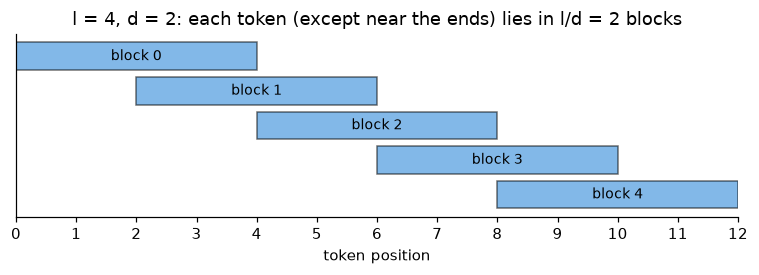

PASS  the block-count formula holds for 27 (T, l, d) combinations


In [2]:
T, l, d = 12, 4, 2
tokens = torch.arange(T)
blocks = tokens.unfold(0, l, d)                       # unfold(dim, size, step): every window of `l` tokens, one window every `d`
print(blocks)
Nc = (T - l) // d + 1
check("number of blocks = (T - l) // d + 1", blocks.shape[0] == Nc == 5, f"{blocks.shape[0]} blocks")

fig, ax = plt.subplots(figsize=(7, 2.6))
for j in range(Nc): ax.barh(j, l, left=j * d, color=CMP_C, alpha=.55, edgecolor="k")
for j in range(Nc): ax.text(j * d + l / 2, j, f"block {j}", ha="center", va="center", fontsize=9)
ax.set_xlim(0, T); ax.set_yticks([]); ax.set_xticks(range(T + 1)); ax.set_xlabel("token position"); ax.invert_yaxis(); ax.grid(False)
ax.set_title("l = 4, d = 2: each token (except near the ends) lies in l/d = 2 blocks"); plt.tight_layout(); plt.show()

ok = all(torch.arange(Tt).unfold(0, ll, dd).shape[0] == (Tt - ll) // dd + 1 for Tt in (32, 100, 257) for ll in (4, 8, 32) for dd in (2, 4, 16) if dd <= ll)
check("the block-count formula holds for 27 (T, l, d) combinations", ok)

**Definition (the paper's equation 7).** For tokens `k_1 ... k_t`, the compressed keys are

&nbsp;&nbsp;&nbsp;&nbsp;`K~_cmp = { phi( k_{i d + 1 : i d + l} )  for 0 <= i <= (t - l)/d }`

where `l` is the block length, `d` the stride between block starts, and `phi` a learnable network that maps a block of keys to one vector. Values are compressed the same way with their own `phi`. The paper says it usually sets `d < l` "to mitigate information fragmentation". We test exactly that in a later section instead of taking it on trust.

## Squeezing a block into one vector

The simplest `phi` is **mean pooling**: average the block's vectors. It has two weaknesses. It cannot learn anything, and it is blind to order (the block "A then B" and "B then A" average to the same vector). The paper describes `phi` as "a learnable MLP with intra-block position encoding"; it does not publish more detail than that, so the version below is *our reading*:

1. add a learnable position vector to each of the `l` slots in the block (the "intra-block position encoding"),
2. flatten the block into one long vector,
3. pass it through a two-layer MLP (multi-layer perceptron).

One addition of ours, not from the paper: we initialise the last MLP layer to zero and add the plain block mean on top, so training *starts* as mean pooling and learns a correction. We did this because from a random start the compressed keys carry no usable signal early in training; we flag it again where it matters.

In [3]:
class Compressor(nn.Module):
    """Squeeze every block of `l` consecutive keys (or values) into ONE vector.
    Blocks start every `d` tokens; d < l means neighbouring blocks overlap (paper: l=32, d=16).
    phi = learnable position embedding inside the block -> flatten -> small MLP."""
    def __init__(self, dim, l, d):
        super().__init__(); self.l, self.d = l, d
        self.pos = nn.Parameter(torch.zeros(l, dim))                           # intra-block position encoding
        self.mlp = nn.Sequential(nn.Linear(l * dim, dim), nn.GELU(), nn.Linear(dim, dim))
        nn.init.zeros_(self.mlp[2].weight); nn.init.zeros_(self.mlp[2].bias)   # our choice: start as plain mean-pooling, learn a correction
    def forward(self, x):                                                      # x: (B, G, T, dim)
        blocks = x.unfold(2, self.l, self.d).transpose(-1, -2)                 # (B, G, Nc, l, dim): the overlapping blocks
        return blocks.mean(-2) + self.mlp((blocks + self.pos).flatten(-2))     # (B, G, Nc, dim)   mean-pool + learned phi

def n_compressed(T, l, d): return (T - l) // d + 1

def compressed_valid(T, l, d, device="cpu"):
    """(T, Nc) bool. Compressed block j covers tokens [j*d, j*d + l). Query t may use it only if ALL of its
    tokens are <= t (otherwise the block would leak the future)."""
    j = torch.arange(n_compressed(T, l, d), device=device); t = torch.arange(T, device=device)
    return (j[None, :] * d + l - 1) <= t[:, None]

def compressed_attention(q, k_cmp, v_cmp, valid):
    """q (B,G,H,T,dk) attends to the compressed keys. Returns (output, attention weights p_cmp (B,G,H,T,Nc))."""
    s = torch.einsum("bghtd,bgcd->bghtc", q, k_cmp) / math.sqrt(q.shape[-1])
    p = s.masked_fill(~valid, NEG).softmax(-1) * valid                          # zero out invalid blocks (and empty rows)
    return torch.einsum("bghtc,bgcd->bghtd", p, v_cmp), p

In [4]:
torch.manual_seed(0)
comp = Compressor(dim=8, l=4, d=2)
x = torch.randn(1, 1, 12, 8)                                    # (batch, groups, tokens, dim)
y = comp(x)
print("tokens", tuple(x.shape), "->  compressed", tuple(y.shape))
check("12 tokens, l=4, d=2 compress to 5 vectors", y.shape == (1, 1, 5, 8))
check("at initialisation phi is exactly mean pooling", torch.allclose(y, x.unfold(2, 4, 2).mean(-1), atol=1e-6))

# order sensitivity: reverse the first block's tokens
x_rev = x.clone(); x_rev[:, :, 0:4] = x[:, :, [3, 2, 1, 0]]
same_mean = torch.allclose(x.unfold(2, 4, 2).mean(-1)[:, :, 0], x_rev.unfold(2, 4, 2).mean(-1)[:, :, 0], atol=1e-6)
nn.init.normal_(comp.mlp[2].weight, std=0.5); nn.init.normal_(comp.pos, std=0.5)       # pretend training made the correction non-zero
differs = not torch.allclose(comp(x)[:, :, 0], comp(x_rev)[:, :, 0], atol=1e-4)
check("mean pooling cannot tell a block from its reversal", same_mean)
check("with the position-aware MLP active, the compressed vector depends on token order", differs)

big = Compressor(dim=192, l=32, d=16)                            # the paper's key dimension and block length
print(f"our phi at the paper's sizes (d_k=192, l=32): {sum(p.numel() for p in big.parameters()):,} parameters per compressor (one for keys, one for values)")

tokens (1, 1, 12, 8) ->  compressed (1, 1, 5, 8)
PASS  12 tokens, l=4, d=2 compress to 5 vectors
PASS  at initialisation phi is exactly mean pooling
PASS  mean pooling cannot tell a block from its reversal
PASS  with the position-aware MLP active, the compressed vector depends on token order
our phi at the paper's sizes (d_k=192, l=32): 1,223,040 parameters per compressor (one for keys, one for values)


## Making compression causal

During training every position is a query at once, so we must make sure a query cannot peek at the future through a block that extends past it. The rule: query `t` may use compressed block `j` only if **every token of the block is at or before `t`**, i.e. `j*d + l - 1 <= t`. A query near the start of the sequence has no complete block yet. We give such queries a zero output from this branch (the other two branches still work); the paper does not say how it handles this edge, so that is our choice.

Number of blocks visible to query `t` (0-indexed): `(t + 1 - l) // d + 1` once `t + 1 >= l`.

PASS  blocks visible to query t = (t+1-l)//d + 1, and 0 before the first block completes


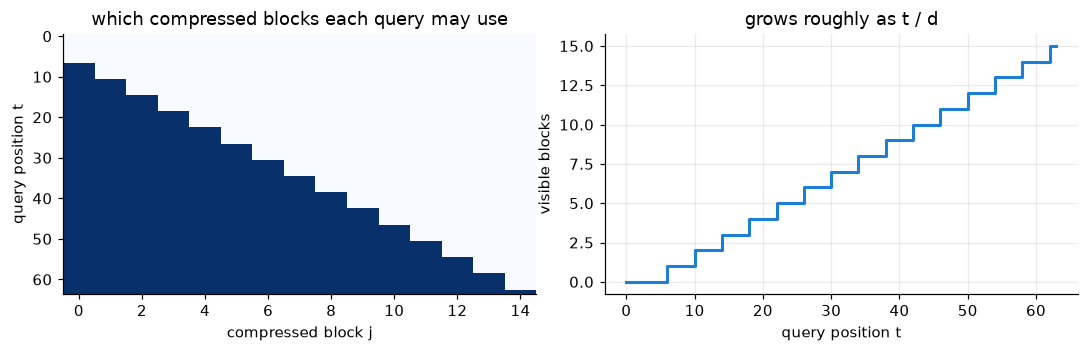

In [5]:
T, l, d = 64, 8, 4
valid = compressed_valid(T, l, d)
visible = valid.sum(1)
formula = torch.where(torch.arange(T) + 1 >= l, (torch.arange(T) + 1 - l) // d + 1, torch.zeros(T, dtype=torch.long))
check("blocks visible to query t = (t+1-l)//d + 1, and 0 before the first block completes", torch.equal(visible, formula))
fig, axs = plt.subplots(1, 2, figsize=(10, 3.3))
axs[0].imshow(valid, cmap="Blues", aspect="auto", origin="upper"); axs[0].set_xlabel("compressed block j"); axs[0].set_ylabel("query position t"); axs[0].set_title("which compressed blocks each query may use"); axs[0].grid(False)
axs[1].step(range(T), visible, color=CMP_C, lw=2); axs[1].set_xlabel("query position t"); axs[1].set_ylabel("visible blocks"); axs[1].set_title("grows roughly as t / d")
plt.tight_layout(); plt.show()

Now the compressed attention itself: the query attends to compressed keys exactly as in ordinary attention, only over a much shorter list. It returns the output *and* the attention weights; part 2 will reuse those weights to decide which blocks deserve a closer look.

To prove causality rather than assert it, we scramble every token from position 40 onward and check that no output before position 40 moves.

In [6]:
torch.manual_seed(1)
B, G, H, T, dk = 1, 1, 2, 64, 16
q, k, v = torch.randn(B, G, H, T, dk), torch.randn(B, G, T, dk), torch.randn(B, G, T, dk)
ck, cv = Compressor(dk, 8, 4), Compressor(dk, 8, 4)
nn.init.normal_(ck.mlp[2].weight, std=0.3); nn.init.normal_(cv.mlp[2].weight, std=0.3)          # make phi non-trivial for the test
valid = compressed_valid(T, 8, 4)
out, p = compressed_attention(q, ck(k), cv(v), valid)
k2, v2 = k.clone(), v.clone(); k2[:, :, 40:] = torch.randn_like(k2[:, :, 40:]); v2[:, :, 40:] = torch.randn_like(v2[:, :, 40:])
out2, _ = compressed_attention(q, ck(k2), cv(v2), valid)
print("output", tuple(out.shape), "  weights", tuple(p.shape), "  (queries x compressed blocks)")
check("scrambling tokens 40+ leaves every output at positions < 40 unchanged (causal)", (out[..., :40, :] - out2[..., :40, :]).abs().max() < 1e-6)
check("scrambling tokens 40+ DOES change later outputs (the test has teeth)", (out[..., 40:, :] - out2[..., 40:, :]).abs().max() > 1e-3)
check("each query's compressed-attention weights sum to 1 (0 while no block is complete)", torch.allclose(p.sum(-1)[..., 7:], torch.ones(B, G, H, T - 7), atol=1e-5) and p.sum(-1)[..., :7].abs().max() == 0)

output (1, 1, 2, 64, 16)   weights (1, 1, 2, 64, 15)   (queries x compressed blocks)
PASS  scrambling tokens 40+ leaves every output at positions < 40 unchanged (causal)
PASS  scrambling tokens 40+ DOES change later outputs (the test has teeth)
PASS  each query's compressed-attention weights sum to 1 (0 while no block is complete)


## Why blocks should overlap

Suppose the thing a query is looking for is a short *run* of tokens (a name, a number, a phrase) that happens to sit across a block boundary. With non-overlapping blocks (`d = l`) the run is cut in two and each half is diluted in a different block. With overlapping blocks (`d = l/2`) some block always contains the whole run. This is what the paper calls **information fragmentation**.

We measure it with mean pooling as `phi` (so the result does not depend on training). The "needle" is a run of `m = 4` tokens; the block length is `l = 8`. For every possible needle position we compute the fraction of the needle contained in the best block.

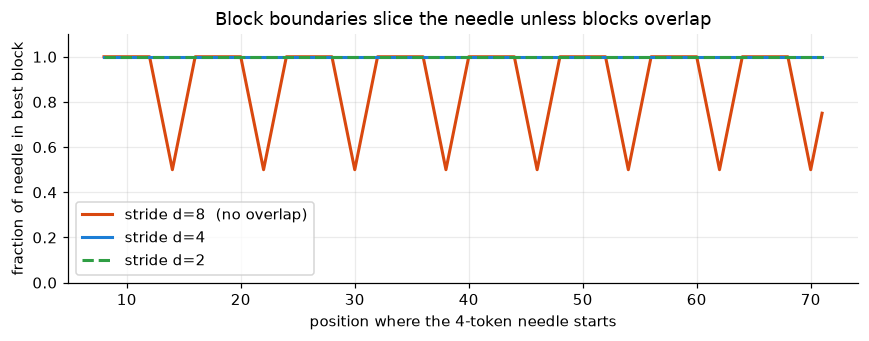

worst case over positions:  d=8 -> 0.50   d=4 -> 1.00   d=2 -> 1.00
PASS  with d = l the needle can be cut in half (worst-case fraction 0.5)
PASS  with d = l/2 the whole needle always fits in some block


In [7]:
def best_block_fraction(offset, l, d, m, T=96):
    """Fraction of a needle of m tokens (starting at `offset`) that fits in the best single block."""
    ind = torch.zeros(T); ind[offset:offset + m] = 1
    return ind.unfold(0, l, d).sum(1).max().item() / m

l, m = 8, 4
offs = list(range(8, 72))
curves = {d: [best_block_fraction(o, l, d, m) for o in offs] for d in (8, 4, 2)}
fig, ax = plt.subplots(figsize=(8, 3.2))
for d, c, ls in [(8, SLC_C, "-"), (4, CMP_C, "-"), (2, WIN_C, "--")]: ax.plot(offs, curves[d], color=c, ls=ls, lw=2, label=f"stride d={d}" + ("  (no overlap)" if d == l else ""))
ax.set_xlabel("position where the 4-token needle starts"); ax.set_ylabel("fraction of needle in best block"); ax.set_ylim(0, 1.1); ax.legend(loc="lower left"); ax.set_title("Block boundaries slice the needle unless blocks overlap"); plt.tight_layout(); plt.show()
print(f"worst case over positions:  d=8 -> {min(curves[8]):.2f}   d=4 -> {min(curves[4]):.2f}   d=2 -> {min(curves[2]):.2f}")
check("with d = l the needle can be cut in half (worst-case fraction 0.5)", abs(min(curves[8]) - 0.5) < 1e-9)
check("with d = l/2 the whole needle always fits in some block", min(curves[4]) == 1.0)

So much for the geometry. Does it change *retrieval*? A noisy test: 256 random key vectors (64-dimensional), a 4-token needle planted at a random position (each needle key = noise + a signal along direction `u`), and a query equal to `u`. We score each compressed block with the dot product with the query and ask: **does the top-scoring block contain the whole needle?** 3,000 trials per setting.

In [8]:
def needle_trial_hit_rate(l, d, m=4, beta=3.0, T=256, dim=64, trials=3000, seed=0):
    g = torch.Generator().manual_seed(seed)
    u = F.normalize(torch.randn(dim, generator=g), dim=0)
    keys = torch.randn(trials, T, dim, generator=g)
    pos = torch.randint(8, T - 8 - m, (trials,), generator=g)
    for t in range(trials): keys[t, pos[t]:pos[t] + m] += beta * u
    blocks = keys.unfold(1, l, d).mean(-1)                          # (trials, Nc, dim): mean-pooled compressed keys
    best = (blocks @ u).argmax(1)                                    # top-scoring block for each trial
    start = best * d
    return ((start <= pos) & (start + l >= pos + m)).float().mean().item()   # does that block contain the entire needle?

l = 8
rates = {d: needle_trial_hit_rate(l, d) for d in (8, 4, 2)}
for d, r in rates.items(): print(f"l={l}, stride d={d}: top block holds the whole needle in {r:.1%} of trials")
check("overlapping blocks (d=l/2) retrieve the needle more often than non-overlapping (d=l)", rates[4] > rates[8] + 0.05, f"{rates[4]:.1%} vs {rates[8]:.1%}")

l=8, stride d=8: top block holds the whole needle in 61.5% of trials
l=8, stride d=4: top block holds the whole needle in 89.5% of trials
l=8, stride d=2: top block holds the whole needle in 94.3% of trials
PASS  overlapping blocks (d=l/2) retrieve the needle more often than non-overlapping (d=l)   [89.5% vs 61.5%]


**What we found and what it costs.** Halving the stride raised the hit rate over the non-overlapping case (numbers above), and halving it again gave a smaller further gain; the price of overlap is *twice as many compressed tokens per halving* (stride 4 has 2x the blocks of stride 8). Yuan et al. chose `d = l/2` (16 and 32). We tested one block length, one needle length and one noise level with a training-free `phi`; we make no claim about the best stride in a trained model.

## What compression blurs

Averaging 32 tokens into one vector is lossy. Take a different needle: a **single** token carrying a signal, and ask the compressed block that contains it to stand out against the noise of everything else. The signal in a mean-pooled block shrinks as `1/l` while the noise only shrinks as `1/sqrt(l)`, so the signal-to-noise ratio falls as `1/sqrt(l)` as blocks grow.

block length l=  4: top compressed block contains the needle token in 71.9% of trials   (random guess: 0.8%)
block length l=  8: top compressed block contains the needle token in 49.8% of trials   (random guess: 1.6%)
block length l= 16: top compressed block contains the needle token in 36.4% of trials   (random guess: 3.2%)
block length l= 32: top compressed block contains the needle token in 31.5% of trials   (random guess: 6.5%)
block length l= 64: top compressed block contains the needle token in 35.9% of trials   (random guess: 13.3%)
block length l=128: top compressed block contains the needle token in 46.0% of trials   (random guess: 28.6%)


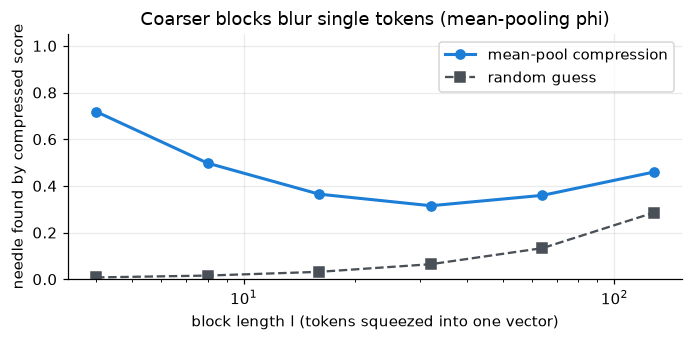

PASS  longer blocks make a single token harder to find (hit rate at l=32 at least 20 points below l=4)   [71.9% -> 31.5%]
PASS  compression still beats a random guess at every block length


In [9]:
def single_needle_hit_rate(l, beta=6.0, T=512, dim=64, trials=2000, seed=1):
    g = torch.Generator().manual_seed(seed); d = l // 2
    u = F.normalize(torch.randn(dim, generator=g), dim=0)
    keys = torch.randn(trials, T, dim, generator=g); pos = torch.randint(l, T - l, (trials,), generator=g)
    keys[torch.arange(trials), pos] += beta * u
    best = (keys.unfold(1, l, d).mean(-1) @ u).argmax(1); start = best * d
    return ((start <= pos) & (start + l > pos)).float().mean().item()          # top block contains the needle token

ls = [4, 8, 16, 32, 64, 128]; hit = [single_needle_hit_rate(l_) for l_ in ls]
chance = [2 / ((512 - l_) // (l_ // 2) + 1) for l_ in ls]                      # token lies in 2 blocks; random guess among Nc blocks
for l_, h, c in zip(ls, hit, chance): print(f"block length l={l_:>3d}: top compressed block contains the needle token in {h:.1%} of trials   (random guess: {c:.1%})")
fig, ax = plt.subplots(figsize=(6.4, 3.2)); ax.semilogx(ls, hit, "o-", color=CMP_C, lw=2, label="mean-pool compression"); ax.semilogx(ls, chance, "s--", color=FULL_C, lw=1.5, label="random guess"); ax.legend(); ax.set_xlabel("block length l (tokens squeezed into one vector)"); ax.set_ylabel("needle found by compressed score")
ax.set_title("Coarser blocks blur single tokens (mean-pooling phi)"); ax.set_ylim(0, 1.05); plt.tight_layout(); plt.show()
check("longer blocks make a single token harder to find (hit rate at l=32 at least 20 points below l=4)", hit[3] < hit[0] - 0.2, f"{hit[0]:.1%} -> {hit[3]:.1%}")
check("compression still beats a random guess at every block length", all(h > c for h, c in zip(hit, chance)))

This is the key limitation, and we measured it: a **training-free** mean-pool compressor loses single tokens as blocks grow (the paper's `l = 32` sits near the bottom of our curve at 31.5%). Past `l = 32` the rate creeps back up only because T is fixed at 512, which leaves fewer blocks to compete with; the dashed line shows the random-guess level that rises for the same reason. NSA's learned `phi` can do better than a mean, and we did not test how much better; Yuan et al. do not isolate it either. What the paper does is *not rely on compression alone*: the compressed branch tells the model *roughly where* to look, and the selection branch (part 2) then reads the chosen blocks at full resolution.

## What compression costs

Two costs: running attention over the compressed keys, and running `phi` itself. Counting multiply-adds at the paper's sizes for one 64k-token sequence, one key/value group of 16 query heads (our estimate, not a measurement):

In [10]:
T_, l_, d_, dk_, dv_, Hq = 65536, 32, 16, 192, 128, 16
t = np.arange(T_)
vis = np.where(t + 1 >= l_, (t + 1 - l_) // d_ + 1, 0)                          # blocks visible to each query
attn_cmp = Hq * vis.sum() * 2 * (dk_ + dv_)                                     # QK^T + AV over compressed blocks, all heads of the group
attn_full = Hq * (T_ * (T_ + 1) / 2) * 2 * (dk_ + dv_)                          # what full attention would cost
Nc = (T_ - l_) // d_ + 1
phi_flops = Nc * 2 * ((l_ * dk_ * dk_ + dk_ * dk_) + (l_ * dv_ * dv_ + dv_ * dv_))   # phi for keys and values, once per group
print(f"full attention            : {attn_full / 1e12:8.2f} TFLOPs")
print(f"compressed attention      : {attn_cmp / 1e12:8.2f} TFLOPs   ({attn_full / attn_cmp:.0f}x fewer)")
print(f"phi (compressing K and V) : {phi_flops / 1e12:8.3f} TFLOPs   ({100 * phi_flops / attn_cmp:.1f}% on top of compressed attention)")
check("at the paper's sizes the compressed attention does about 16x fewer multiply-adds than full attention", 15 < attn_full / attn_cmp < 17, f"{attn_full / attn_cmp:.1f}x")
check("the compressor adds only a small overhead (< 20% of the compressed attention)", phi_flops < 0.2 * attn_cmp, f"{100 * phi_flops / attn_cmp:.1f}%")
check("compressed tokens at 64k with l=32, d=16: 4,095", Nc == 4095)

full attention            :    21.99 TFLOPs
compressed attention      :     1.37 TFLOPs   (16x fewer)
phi (compressing K and V) :    0.014 TFLOPs   (1.0% on top of compressed attention)
PASS  at the paper's sizes the compressed attention does about 16x fewer multiply-adds than full attention   [16.0x]
PASS  the compressor adds only a small overhead (< 20% of the compressed attention)   [1.0%]
PASS  compressed tokens at 64k with l=32, d=16: 4,095


(We expected a different ratio at first, because the average causal query sees only half of the blocks. But it also sees only half of the tokens in full attention, so the causal halving cancels and the total saving equals the per-query 16x. The counting check above caught our mistake.)

## Closing thoughts

Compression gives every query a cheap, always-available overview of the whole past, at a cost we estimated as a small fraction of the full attention it replaces. It also loses precise detail, and we measured that loss with a training-free compressor rather than assume it. The paper's own evidence for this branch comes only from end-to-end results, not from an ablation of compression alone, so we do not claim a measured contribution for it beyond what we show here.

**Claims in this notebook that lack a number or baseline, for you to decide on:** (1) the learned `phi` is our design reading of one sentence in the paper, and its zero-init-plus-mean is our addition; (2) the overlap and blur experiments use a training-free mean-pool compressor, so they bound a *learned* compressor only loosely; (3) the FLOP counts are our arithmetic, not timings.

In [11]:
print(f"{sum(ok for _, ok in CHECKS)}/{len(CHECKS)} checks passed")
for n, ok in CHECKS:
    if not ok: print("FAILED:", n)
assert all(ok for _, ok in CHECKS), "some checks failed"

18/18 checks passed
